![UC4D Explorer.png](<attachment:UC4D Explorer.png>)
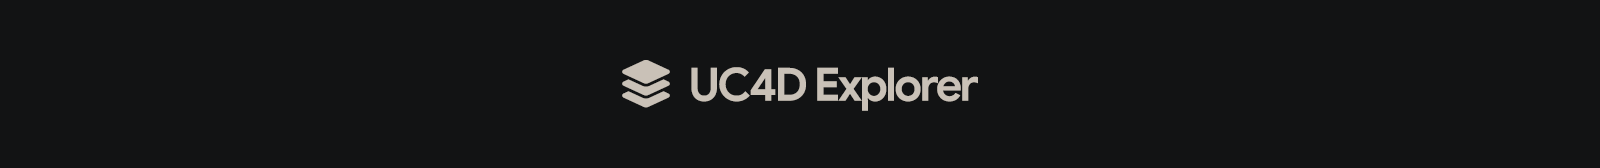

| | |
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |
| **Cities** | Tehran · Singapore |
| **Access** | Read-only. The published assets are globally readable, any Earth Engine cloud project works. |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

---

#### **Overview**

The UC4D Cube Is a Set of Multi-Tier, Multi-Season Rasters for Two Cities, Published as Earth Engine Assets. This Notebook Is the Reference Client for It. It Does Three Jobs: It **Verifies** That the Assets Are Reachable, It Lets You **Explore** Any Layer Interactively, and It **Extracts** Analysis-Ready Data (Tables, Lazy `Xarray` Cubes, Zarr Stores) From a Few Lines of Code.

| Step | Section | What Happens |
|:--:|:--|:--|
| 1 | §1–§3 | Installs and Imports the Libraries, Loads the Configuration, and Connects to Earth Engine. |
| 2 | §4 | Builds the Layer Catalogue (Every Band, Its Group, Scale Factor and Unit) and Its Color Ramps. |
| 3 | §5 | Defines the `UC4D` Client: One Object per City, Tier, Season and Year That Returns an `ee.Image`, an `Xarray` Dataset or a Domain. |
| 4 | §6 | Audits Every Expected Asset Path and Lists Anything Missing. |
| 5 | §7–§9 | Renders Maps, Samples Point Profiles, and Launches the Interactive Explorer. |
| 6 | §10–§11 | Computes Regional Statistics Headlessly and Exports Bands to Zarr. |

#### **Tiers**

| Tier | Resolution | Time Axis | Notes |
|:--|:--|:--|:--|
| **FINP** | 10 m | 4 Seasons × 2020–2025 | Fine-Scale Product. Owns the Shared *Static* Asset (Topography, 3D Morphology). |
| **CORP** | 926.6 m | 4 Seasons × 2020–2025 | Coarse Tier Built on VIIRS. Values Are Stored in Physical Units. |
| **LCZP** | 10 m | Annual, 2020–2025 | Local Climate Zone Product. The Only Tier With **GLCM Texture** Layers. Static Layers Are Read From FINP. |

#### **Seasons**

The Seasons Are Defined by Each City's Own Climate, Not by Calendar Convention.

| City | Season Codes |
|:--|:--|
| Tehran | `SPR` Spring · `SUM` Summer · `AUT` Autumn · `WIN` Winter |
| Singapore | `NEM` Northeast Monsoon · `IM1` First Inter-Monsoon · `SWM` Southwest Monsoon · `IM2` Second Inter-Monsoon |

#### **Layer Groups**

SAR · Spectral Indices · Surface Physics · Optical · Topography · 3D Morphology · Anthropogenic · GLCM Texture (102 Layers in Total; §4 Prints the Exact Count per Group).

#### **Asset Layout**

```text
projects/ee-alirezaali/assets/UC4D/
├── STC/
│   └── <Tier>/<City>/
│       ├── Dynamic/<City>-<Season>-<Year>      ← FINP, CORP (Seasonal)
│       ├── <City>-<Year>                       ← LCZP (Annual)
│       ├── <City>-<Year>-GLCM                  ← LCZP only
│       └── Static/<City>                       ← FINP, CORP (LCZP reads FINP's)
└── Spatial-Domains/
    └── <Holdout|SUHI|Training|LCZ|Complete>-Domain/<City>
```

> **Scaled Integers.** FINP and LCZP store most bands as scaled integers. The Client divides by the layer's scale factor on load. **Optical bands are the exception** — they are delivered as raw digital numbers (DN, 0–10000) and must be divided by 10 000 to obtain reflectance in [0, 1]. All index, physics, topography and anthropogenic bands are in physical units.

---

#### **Before You Begin**

[1] **An Earth Engine project** with the Earth Engine API enabled. It is only used to bill your requests; the UC4D assets themselves are world-readable. Set it in §2.

[2] **A Google Account** registered for Earth Engine. In Colab, §3 opens the sign-in prompt on first run.

[3] **Python 3.10 or later.** On Colab everything except `xee` and `zarr` is preinstalled; §1 installs whatever is missing.

**Suggested Workflow:** run the notebook from the top once. §6 should end with every row showing. After that, the interactive explorer (§9) is the only cell you need to re-run.

**Runtime & Quota.** Each map is one Earth Engine thumbnail request. Each profile is one batched request, and results are cached per session. Both are light. Large exports (§11) are the only heavy step, and they are guarded by a pixel limit.

---

#### **[1] Environment**

In [13]:
# ───────────────
# [1] Environment
# ───────────────

import importlib.util

import subprocess

import sys

# [1.1] Install Missing Packages (import name → pip name)

RequiredPackages = {

    "ee"                 : "earthengine-api"    ,

    "xee"                : "xee"                ,

    "xarray"             : "xarray"             ,

    "zarr"               : "zarr"               ,

    "ipywidgets"         : "ipywidgets"         ,

    "jupyterlab_widgets" : "jupyterlab_widgets" ,

    "pandas"             : "pandas"             ,

    "matplotlib"         : "matplotlib"         ,

    "requests"           : "requests"           ,

    "PIL"                : "pillow"

}

MissingPackages = [ Pip for Module , Pip in RequiredPackages.items() if importlib.util.find_spec(Module) is None ]

if MissingPackages:

    print(f"Installing: {', '.join(MissingPackages)}")

    subprocess.check_call([ sys.executable , "-m" , "pip" , "install" , "-q" , *MissingPackages ])

# [1.2] Imports

import datetime

import functools

import io

import platform

import shutil

import tempfile

import warnings

from concurrent.futures import ThreadPoolExecutor

from importlib import metadata

from pathlib import Path

from types import SimpleNamespace

import ee

import ipywidgets as widgets

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

import requests

import xarray as xr

from IPython.display import display

from matplotlib import font_manager as FontManager

from matplotlib.colors import LinearSegmentedColormap

from PIL import Image

from requests.adapters import HTTPAdapter

from urllib3.util.retry import Retry

warnings.filterwarnings( "ignore" , category = FutureWarning )

warnings.filterwarnings( "ignore" , category = UserWarning )

IsColab = "google.colab" in sys.modules

def PackageVersion(PackageName):

    """Return The Installed Version of a Package, or 'Not Installed'."""

    try:

        return metadata.version(PackageName)

    except metadata.PackageNotFoundError:

        return "Not Installed"

# [1.3] Environment

print("\n———————————")
print("Environment")
print("———————————")

print(f"\n  Run Started (UTC) : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"\n  Platform          : {'Google Colab' if IsColab else platform.platform()}")

print(f"\n  Python            : {platform.python_version()}")

for PackageName in ( "earthengine-api" , "xee" , "xarray" , "zarr" , "ipywidgets" , "pandas" , "matplotlib" ):

    print(f"\n  {PackageName:<18}: {PackageVersion(PackageName)}")

# ─────────────────
# [1.4] EB Garamond
# ─────────────────

DriveRoot  = Path('/content/drive/MyDrive')

FontDir    = next((D for D in (DriveRoot / 'Fonts' / 'EB Garamond', DriveRoot / 'UC4D' / 'Fonts' / 'EB Garamond') if D.exists()), None)

FontTemp   = Path(tempfile.gettempdir()) / 'EBGaramond'

FontStyles = [ 'Regular' , 'Italic' , 'Medium' , 'SemiBold' , 'Bold' , 'BoldItalic' ]

FontFamily = 'DejaVu Serif'

FontManager.fontManager.ttflist = [ 

    F for F in FontManager.fontManager.ttflist

    if not str(F.fname).startswith(str(DriveRoot)) and 'EBGaramond.ttf' not in str(F.fname)

]

if FontDir is not None:

    try:

        FontTemp.mkdir( exist_ok = True )

        for Style in FontStyles:

            Destination = FontTemp / f'EBGaramond-{Style}.ttf'

            if not Destination.exists():

                shutil.copy(FontDir / f'EBGaramond-{Style}.ttf', Destination)

            FontManager.fontManager.addfont(str(Destination))

        FontFamily = 'EB Garamond'

    except Exception as Error:

        print(f'\nEB Garamond Not Registered, Falling Back To {FontFamily}: {Error}')


———————————
Environment
———————————

  Run Started (UTC) : 2026-11-06 21:00:37

  Platform          : Google Colab

  Python            : 3.13.18

  earthengine-api   : 1.7.39

  xee               : 0.1.2

  xarray            : 2025.12.0

  zarr              : 3.4.2

  ipywidgets        : 7.7.1

  pandas            : 2.2.3

  matplotlib        : 3.10.0


---

#### **[2] Configuration**

| Setting | Purpose |
|:--|:--|
| `GEEProject` | **Your** Earth Engine cloud project. Used only to run requests, change it to yours. |
| `AssetRoot` | The published UC4D assets. World readable and fixed, do not change it. |
| `Years` | Years covered by the cube. |
| `Cities` | Per-city season codes, season Colors, and the map centre used as the default sampling point. |
| `Tiers` | Per-tier resolution and storage rules: `ScaledInt` (Stored as scaled integers), `Annual` (Yearly), `StaticFrom` (Which tier owns the shared *Static* asset), `SampleScale` and `StatScale` (Reduction scales in metres for points and regions). |
| `Domains` | Spatial Domains the explorer can outline. |
| `Basemap` | The Sentinel-2 composite drawn beneath every layer. |
| `Defaults` | What the explorer shows when it first opens. |
| `RunHeadlessDemo`, `RunZarrDemo` | Switch the §10 and §11 demonstrations on or off. |

In [14]:
# —————————————————
# [2] Configuration
# —————————————————

# [2.1] Earth Engine

GEEProject    = "ee-alirezaali"  # Change to your project.

AssetRoot     = "projects/ee-alirezaali/assets/UC4D"

Assets        = SimpleNamespace( STC = f"{AssetRoot}/STC" , Domains = f"{AssetRoot}/Spatial-Domains" )

HighVolumeURL = "https://earthengine-highvolume.googleapis.com"

# [2.2] Time

Years = [ 2020 , 2021 , 2022 , 2023 , 2024 , 2025 ]

# [2.3] Cities

#   Seasons      : Season Codes In Chronological Order Of The City's Own Climate.

#   SeasonNames  : Long Names (Shown In The §2 Summary).

#   SeasonColors : One Color Per Season, Used In Every Plot.

#   Center       : [lon, lat], The Default Sampling Point.

Cities = {

    "Tehran": SimpleNamespace(

        Seasons      = [ "SPR" , "SUM" , "AUT" , "WIN" ]                 ,

        SeasonNames  = [ "Spring" , "Summer" , "Autumn" , "Winter" ]     ,

        SeasonColors = [ "#3d7a45" , "#e8242c" , "#f5821f" , "#5262b5" ] ,

        Center       = [ 51.389 , 35.689 ]

    ),

    "Singapore": SimpleNamespace(

        Seasons      = [ "NEM" , "IM1" , "SWM" , "IM2" ]                                                     ,

        SeasonNames  = [ "Northeast Monsoon" , "Inter-monsoon 1" , "Southwest Monsoon" , "Inter-monsoon 2" ] ,

        SeasonColors = [ "#5b9bd5" , "#f5a01a" , "#d6454f" , "#7b4aa6" ]                                     ,

        Center       = [ 103.82 , 1.352 ]

    )

}

CityNames = list(Cities)

# [2.4] Tiers

Tiers = {
  
    "FINP" : SimpleNamespace( Resolution = "10 m" , ScaledInt = True , Annual = False , StaticFrom = "FINP" , SampleScale = 30 , StatScale = 100 )        ,
  
    "CORP" : SimpleNamespace( Resolution = "926.6 m" , ScaledInt = False , Annual = False , StaticFrom = "CORP" , SampleScale = 200 , StatScale = 926.6 ) ,
  
    "LCZP" : SimpleNamespace( Resolution = "10 m" , ScaledInt = True , Annual = True , StaticFrom = "FINP" , SampleScale = 30 , StatScale = 100 )

}

TierNames = list(Tiers)

# [2.5] Spatial Domains

DomainTypes       = [ "Holdout" , "SUHI" , "Training" , "LCZ" , "Complete"]

DomainNone        = "None"

DomainFillOpacity = 0.25

DomainColors = {

    "Holdout"  : "#e53935" ,
    
    "SUHI"     : "#fb8c00" ,
    
    "Training" : "#1a73e8" ,
    
    "LCZ"      : "#8e24aa" ,
    
    "Complete" : "#188038"

}

# [2.6] Basemap (Sentinel-2 RGB Median Under Every Layer)

Basemap = SimpleNamespace(

    Collection = "COPERNICUS/S2_SR_HARMONIZED" ,

    Start      = "2025-01-01"                  ,

    End        = "2025-12-30"                  ,

    MaxCloud   = 5                             ,

    Bands      = [ "B4" , "B3" , "B2" ]        ,

    Vis        = { "min" : 200 , "max" : 2800 , "gamma" : 1.2 }

)

# [2.7] Explorer Defaults & Display

Defaults           = SimpleNamespace( City = "Tehran" , Tier = "FINP" , Year = 2024 , Layer = "NDVI" , Domain = "Holdout" , Opacity = 1.0 )

OpacitySteps       = [ 1.0 , 0.9 , 0.8 , 0.7 , 0.6 , 0.5 , 0.4 , 0.3 , 0.2 , 0.1 ]

ThumbDimensions    = 768

ProfileMaxPixels   = 1e9

AutoStretchPercent = ( 2 , 98 )

FallbackVis        = { "min" : 0 , "max" : 1 , "palette" : [ "#000000" , "#ffffff" ] }

AutoPalette        = [ "#440154" , "#3b528b" , "#21908d" , "#5dc863" , "#fde725" ]

Ink                = SimpleNamespace( Text = "#202124" , Muted = "#5f6368" , Dark = "#3c4043" , Grid = "#dadce0" )

# [2.8] Demonstrations (§10 and §11)

RunHeadlessDemo = True

RunZarrDemo     = False

ZarrDemoPath    = "UC4D-Demo.zarr"

MaxExportPixels = 5e7

# ————————————————
# Derived Settings
# ————————————————

if Defaults.City not in Cities:
 
    raise ValueError(f"Defaults.City Must Be One Of {CityNames}; Got {Defaults.City!r}.")

if Defaults.Tier not in Tiers:
 
    raise ValueError(f"Defaults.Tier Must Be One Of {TierNames}; Got {Defaults.Tier!r}.")

if Defaults.Year not in Years:
 
    raise ValueError(f"Defaults.Year Must Be One Of {Years}; Got {Defaults.Year!r}.")

if Defaults.Domain not in DomainTypes + [DomainNone]:
 
    raise ValueError(f"Defaults.Domain Must Be One Of {DomainTypes + [DomainNone]}; Got {Defaults.Domain!r}.")

for CityName, City in Cities.items():

    if not (len(City.Seasons) == len(City.SeasonNames) == len(City.SeasonColors)):
 
        raise ValueError(f"{CityName}: Seasons, SeasonNames And SeasonColors Must Have The Same Length.")

print(f"Compute Project : {GEEProject}")

print(f"\nAsset Root      : {AssetRoot}")

print(f"\nYears           : {Years[0]}–{Years[-1]} ({len(Years)})")

for CityName, City in Cities.items():

    print(f"\n{CityName:<15} : " + " · ".join(f"{Code} {Name}" for Code, Name in zip(City.Seasons, City.SeasonNames)))

print(f"\nTiers           : " + " · ".join(f"{Name} ({Tier.Resolution}{', Annual' if Tier.Annual else ''})" for Name, Tier in Tiers.items()))

Compute Project : ee-alirezaali

Asset Root      : projects/ee-alirezaali/assets/UC4D

Years           : 2020–2025 (6)

Tehran          : SPR Spring · SUM Summer · AUT Autumn · WIN Winter

Singapore       : NEM Northeast Monsoon · IM1 Inter-monsoon 1 · SWM Southwest Monsoon · IM2 Inter-monsoon 2

Tiers           : FINP (10 m) · CORP (926.6 m) · LCZP (10 m, Annual)


---

#### **[3] Session Setup**

In [15]:
# —————————————————
# [3] Session Setup
# —————————————————

# [3.1] Earth Engine

def InitializeEarthEngine():

    """Initialise Earth Engine on the High-Volume Endpoint, Running the Interactive Sign-in First If Needed."""

    try:

        ee.Initialize( project = GEEProject , opt_url = HighVolumeURL )

    except Exception:

        print("Earth Engine Sign-In Required. Follow the Prompt…")

        ee.Authenticate()

        ee.Initialize( project = GEEProject , opt_url = HighVolumeURL )

    print(f"✅ Earth Engine Initialised (Project : {GEEProject}).")

InitializeEarthEngine()

# [3.2] Confirm the Published Assets Are Readable

try:

    ee.data.getAsset(Assets.STC)

    print(f"✅ UC4D Assets Are Readable: {Assets.STC}")

except ee.EEException as Error:

    raise RuntimeError(f"Cannot Read {Assets.STC}. Check AssetRoot and Your Network. Earth Engine Said: {Error}") from Error

# [3.3] HTTP Session for Thumbnails

Http = requests.Session()

Http.mount("https://", HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))))

✅ Earth Engine Initialised (Project : ee-alirezaali).
✅ UC4D Assets Are Readable: projects/ee-alirezaali/assets/UC4D/STC


---

#### **[4] Layer Catalogue**

Every layer is one entry: its band `Id`, its `Group`, where it lives (`Source`), its integer `Scale` factor and its `Unit`.

| `Source` | Meaning |
|:--|:--|
| `Dynamic` | Varies with Season and Year. Read From the Tier's *Dynamic* Asset (FINP, CORP) or Annual Asset (LCZP). |
| `Static` | Time-invariant (Topography & 3D Morphology). One Asset Per City, Shared Across Years and Seasons. |
| `GLCM` | GLCM Texture. Exists **Only** in the Annual LCZP Tier. Generated for Four Bands × Four Metrics × Four Window Sizes. |

Color ramps are looked up by each layer's `Vis` key. Layers whose `Vis` is `AUTO` (All GLCM Texture) get a **2–98 % Stretch Computed On The Fly** Over the Viewed Domain, Because Their Ranges Differ by Band and Window.

In [16]:
# —————————————————————
# [4.1] Layer Catalogue
# —————————————————————

def MakeLayer( Id , Group , Source , Scale , Unit , Vis = None ):

    return SimpleNamespace( Id = Id , Group = Group , Source = Source , Scale = Scale , Unit = Unit , Vis = Vis or Id )

# (Group, Source, [(ID, Scale, Unit), …])

CatalogueSpec = [ 

    ("SAR", "Dynamic", [ ("VV" , 100 , "dB") , ("VH" , 100 , "dB") , ("Diff" , 100 , "dB") ]),

    ("Index", "Dynamic", [ (Id , 10000 , "Unitless") for Id in ("NDVI", "MSAVI2", "EVI2", "NDRE", "NDMI", "NDWI", "MNDWI", "BSI", "BLFEI")]),

    ("Physics", "Dynamic", [ ("Albedo" , 10000 , "Unitless") , ("FVC" , 10000 , "fraction") , ("Emissivity" , 10000 , "Unitless") ]),

    ("Optical", "Dynamic", [ (Id , 1 , "DN") for Id in ("B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12")]),

    ("Topography", "Static", [ ("Elevation" , 100 , "m") , ("Slope" , 100 , "degrees") , ("Northness", 10000, "Unitless"), ("Eastness", 10000, "Unitless")]),

    ("3D", "Static", [ ("BH" , 100 , "m") , ("SVF" , 10000 , "Unitless") , ("BCR" , 10000 , "fraction") , ("SDH", 100, "m"), ("FAI", 10000, "Unitless")]),

    ("Anthropogenic", "Dynamic", [ ("NTL" , 100 , "nW·cm⁻²·sr⁻¹") , ("PD" , 100 , "people/cell") ]),

]

LayerCatalogue = [ MakeLayer(Id , Group , Source , Scale , Unit) for Group , Source , Rows in CatalogueSpec for Id , Scale , Unit in Rows ]

# [4.1.1] GLCM Texture (Annual LCZP Tier)

GLCMBands   = ( "VH" , "VV" , "SWIR2" , "NIR" )

GLCMMetrics = ( "VAR" , "CONTRAST" , "IDM" , "ENT" )

GLCMWindows = ( 1 , 3 , 7 , 9 )

for Band in GLCMBands:

    for Metric in GLCMMetrics:

        for Window in GLCMWindows:

            LayerCatalogue.append(MakeLayer( f"{Band}-{Metric}-{Window}" , "Texture" , "GLCM" , 1 , "Unitless" , Vis = "AUTO" ))

# [4.1.2] Lookups

LayerById   = { Layer.Id : Layer for Layer in LayerCatalogue }

LayerGroups = list(dict.fromkeys(Layer.Group for Layer in LayerCatalogue))

if Defaults.Layer not in LayerById:

    raise ValueError(f"Defaults.Layer {Defaults.Layer!r} Is Not In The Catalogue.")

def LayerAvailable( Layer , TierName ):

    return Tiers[TierName].Annual if Layer.Source == "GLCM" else True

def LayersFor( TierName , Group = None ):

    return [ Layer.Id for Layer in LayerCatalogue if LayerAvailable( Layer , TierName ) and (Group is None or Layer.Group == Group) ]

# [4.1.3] Catalogue Summary

CatalogueTable = (pd.DataFrame([ vars(Layer) for Layer in LayerCatalogue ])

                  .groupby( "Group" , sort = False )

                  .agg( Layers = ( "Id" , "count" ) , Source = ( "Source" , "first" ) , Examples = ( "Id" , lambda Ids: ", ".join(Ids[:4]) + (" …" if len(Ids) > 4 else "") ) )

                  .reset_index())

display(CatalogueTable)

print(f"\n✅ {len(LayerCatalogue)} Layers In {len(LayerGroups)} Groups.")

,Group,Layers,Source,Examples
0,SAR,3,Dynamic,"VV, VH, Diff"
1,Index,9,Dynamic,"NDVI, MSAVI2, EVI2, NDRE …"
2,Physics,3,Dynamic,"Albedo, FVC, Emissivity"
3,Optical,12,Dynamic,"B1, B2, B3, B4 …"
4,Topography,4,Static,"Elevation, Slope, Northness, Eastness"
5,3D,5,Static,"BH, SVF, BCR, SDH …"
6,Anthropogenic,2,Dynamic,"NTL, PD"
7,Texture,64,GLCM,"VH-VAR-1, VH-VAR-3, VH-VAR-7, VH-VAR-9 …"



✅ 102 Layers In 8 Groups.


In [17]:
# —————————————————
# [4.2] Color Ramps
# —————————————————

VisJsPath = Path('/content/drive/MyDrive/UC4D/Visualization/UC4D-Visualization.js')

def ParseVisualizationJs(JsPath):

    """Extract Every Exports.<Name>Vis / <Name>VisParams Block Into a Python Dict."""

    import re

    Text = Path(JsPath).read_text(encoding='utf-8')

    Text = re.sub(r'//[^\n]*', '', Text)

    Text = re.sub(r'/\*.*?\*/', '', Text, flags=re.DOTALL)

    Pattern = re.compile(r'exports\.(\w+?)(?:VisParams|Vis)\s*=\s*\{(?P<Body>.*?)\}\s*;?', re.DOTALL)

    Out = {}

    for Match in Pattern.finditer(Text):

        Band = Match.group(1)

        Body = Match.group('Body')

        MinMatch = re.search(r'\bmin\s*:\s*([-\d.eE+]+)', Body)

        MaxMatch = re.search(r'\bmax\s*:\s*([-\d.eE+]+)', Body)

        PaletteMatch = re.search(r'\bpalette\s*:\s*\[([^\]]+)\]', Body, re.DOTALL)

        if not (MinMatch and MaxMatch and PaletteMatch):

            continue

        RawColors = re.findall(r"['\"]([^'\"]+)['\"]", PaletteMatch.group(1))

        Palette = []

        for Color in RawColors:

            Clean = Color.strip()

            if re.fullmatch(r'[0-9a-fA-F]{6}', Clean):

                Clean = '#' + Clean

            Palette.append(Clean)

        Out[Band] = {

            'min': float(MinMatch.group(1)),

            'max': float(MaxMatch.group(1)),

            'palette': Palette,

        }

    return Out

VisRamps       = ParseVisualizationJs(VisJsPath)

UnmappedLayers = [Layer.Id for Layer in LayerCatalogue if Layer.Vis != "AUTO" and Layer.Vis not in VisRamps]

if UnmappedLayers:

    raise ValueError(f"No Color Ramp For: {UnmappedLayers}")

def FixedVis(LayerId):

    """The Fixed Color Ramp of a Layer, or None For AUTO Layers."""

    Key = LayerById[LayerId].Vis

    return None if Key == "AUTO" else dict(VisRamps.get(Key, FallbackVis))

print(f"\n✅ {len(VisRamps)} Fixed Color Ramps · {sum(Layer.Vis == 'AUTO' for Layer in LayerCatalogue)} Layers Use An Automatic Stretch.")


✅ 47 Fixed Color Ramps · 64 Layers Use An Automatic Stretch.


---

#### **[5] The UC4D Client**

One `UC4D` Object Is One Slice of the Cube: A **City**, a **Tier**, and (Where the Tier Needs Them) a **Season** and **Year**. From It You Get:

| Method | Returns |
|:--|:--|
| `AssetPath(LayerId)` | The Earth Engine Asset ID That Holds a Band. |
| `Image(LayerId)` | An `ee.Image` of One Band **in Physical Units** (Scaled Integers are Divided by the Layer's Scale Factor). `None` If the Band Does Not Exist at This Tier. |
| `DomainPath(Kind)`, `Domain(Kind)` | The Asset ID of, Or the `ee.FeatureCollection` For, Spatial Domains Set (`Holdout`, `SUHI`, `Training`, `LCZ`, `Complete`). |
| `OpenXarray(LayerId, ScaleMeters, Kind)` | A Lazy `xarray.Dataset` Backed by `xee`. Nothing is Downloaded Until You Compute. |

Seasons are required only for Seasonal tiers (FINP, CORP); `Year` is required for everything except Static layers. A wrong city, tier or season code fails immediately with the list of valid values.

**Note:** OpenXarray and EstimateExport use a single isotropic degrees-per-metre conversion (111,320 m/degree). At mid and high latitudes, effective lon pixel size is cos(lat) smaller than the nominal scale; use a projected CRS via xee if anisotropic pixels matter.

In [18]:
# ———————————————————
# [5] The UC4D Client
# ———————————————————

class UC4D:

    """Read-only client for One Slice (City · Tier · Season · Year) of the Published UC4D Cube."""

    def __init__( self , City , Tier = "FINP" , Season = None , Year = None ):

        if City not in Cities:

            raise ValueError(f"City Must Be One of {CityNames}; Got {City!r}.")

        if Tier not in Tiers:

            raise ValueError(f"Tier Must Be One of {TierNames}; Got {Tier!r}.")

        if Season is not None and Season not in Cities[City].Seasons:

            raise ValueError(f"Season For {City} Must Be One of {Cities[City].Seasons}; Got {Season!r}.")

        if Year is not None and Year not in Years:

            raise ValueError(f"Year Must Be One of {Years}; Got {Year!r}.")

        self.City, self.Tier, self.Season, self.Year = City, Tier, Season, Year

    def __repr__(self):

        Slice = "Annual" if Tiers[self.Tier].Annual else self.Season

        return f"UC4D({self.City} · {self.Tier} · {Slice} · {self.Year})"

    # [5.1] Asset Paths

    def _Require( self , **Fields ):

        Missing = [ Name for Name , Value in Fields.items() if Value is None ]

        if Missing:

            raise ValueError(f"{self!r} Needs {', '.join(Missing)} For This Layer.")

    def DynamicAsset(self):

        """The Tier's Time-Varying Asset: Seasonal (FINP, CORP) or Annual (LCZP)."""

        if Tiers[self.Tier].Annual:

            self._Require( Year = self.Year )

            return f"{Assets.STC}/{self.Tier}/{self.City}/{self.City}-{self.Year}"

        self._Require( Season = self.Season , Year = self.Year )

        return f"{Assets.STC}/{self.Tier}/{self.City}/Dynamic/{self.City}-{self.Season}-{self.Year}"

    def StaticAsset(self):

        """The Time-Invariant Asset. LCZP Reads FINP's (see Tiers[...].StaticFrom)."""

        return f"{Assets.STC}/{Tiers[self.Tier].StaticFrom}/{self.City}/Static/{self.City}"

    def GLCMAsset(self):

        """The Annual Texture Asset (LCZP Only)."""

        self._Require( Year = self.Year )

        return f"{Assets.STC}/{self.Tier}/{self.City}/{self.City}-{self.Year}-GLCM"

    def AssetPath( self , LayerId = None ):

        """Asset ID Holding a Band; with No LayerID, The Dynamic Asset."""

        Layer = LayerById.get(LayerId)

        if Layer is None:

            return self.DynamicAsset()

        return { "Static" : self.StaticAsset , "GLCM" : self.GLCMAsset }.get( Layer.Source , self.DynamicAsset )()

    # [5.2] Earth Engine Image

    def Image( self , LayerId ):

        Layer = LayerById.get(LayerId)

        if Layer is None:

            raise KeyError(f"Unknown Layer {LayerId!r}. See The Catalogue In §4.")

        if not LayerAvailable( Layer , self.Tier ):

            return None

        Band = ee.Image(self.AssetPath(LayerId)).select(LayerId)

        if Tiers[self.Tier].ScaledInt and Layer.Scale > 1:

            Band = Band.toFloat().divide(Layer.Scale).rename(LayerId)

        return Band

    # [5.3] Domains

    def DomainPath( self , Kind = "Holdout" ):

        if Kind not in DomainTypes:

            raise ValueError(f"Domain Kind Must Be One Of {DomainTypes}; Got {Kind!r}.")

        return f"{Assets.Domains}/{Kind}-Domain/{self.City}"

    def Domain( self , Kind = "Holdout" ):

        return ee.FeatureCollection(self.DomainPath(Kind))

    # [5.4] xarray via xee

    def OpenXarray( self , LayerId , ScaleMeters = None , Kind = "Holdout" ):

        Image = self.Image(LayerId)

        if Image is None:

            return None

        ScaleMeters = ScaleMeters or Tiers[self.Tier].StatScale

        return xr.open_dataset(

            Image                            ,

            engine   = "ee"                  ,

            crs      = "EPSG:4326"           ,

            scale    = ScaleMeters / 111_320 ,

            geometry = self.Domain(Kind).geometry().bounds()

        )

print("\n✅ UC4D Client Defined.")

print(f"\n   Example: {UC4D(Defaults.City, Defaults.Tier, Cities[Defaults.City].Seasons[0], Defaults.Year)!r}")


✅ UC4D Client Defined.

   Example: UC4D(Tehran · FINP · SPR · 2024)


---

#### **[6] Verification**

In [19]:
# ————————————————
# [6] Verification
# ————————————————

# [6.1] Expected Assets

def ExpectedAssets():

    Rows = []

    for CityName, City in Cities.items():

        for TierName, Tier in Tiers.items():

            if Tier.Annual:

                for Year in Years:

                    Client = UC4D( CityName , TierName , Year = Year )

                    Rows.append(( CityName , f"{TierName} Annual" , Client.DynamicAsset() ))

                    Rows.append(( CityName , f"{TierName} GLCM" , Client.GLCMAsset() ))

            else:

                for Season in City.Seasons:

                    for Year in Years:

                        Rows.append(( CityName , f"{TierName} Seasonal" , UC4D( CityName , TierName , Season , Year ).DynamicAsset() ))

            Rows.append(( CityName , f"{TierName} Static" , UC4D( CityName , TierName ).StaticAsset() ))

        for Kind in DomainTypes:

            Rows.append(( CityName , "Domains" , UC4D(CityName).DomainPath(Kind) ))

    return list(dict.fromkeys(Rows))

def AssetExists(Path):

    try:

        ee.data.getAsset(Path)

        return True

    except ee.EEException:

        return False

def AuditAssets( Workers = 8 ):

    Rows = ExpectedAssets()

    with ThreadPoolExecutor( max_workers = Workers ) as Pool:

        Found = list(Pool.map( AssetExists , [ Path for _ , _ , Path in Rows ] ))

    Audit   = pd.DataFrame( Rows , columns = [ "City" , "Family" , "Path" ] ).assign( Found = Found )

    Summary = (Audit.groupby( [ "City" , "Family" ] , sort = False )

               .agg( Expected = ( "Found" , "size" ) , Found = ( "Found" , "sum" ) )

               .reset_index())

    Summary["Status"] = np.where( Summary["Found"] == Summary["Expected"] , "✅" , "❌" )

    return Summary, Audit[~Audit["Found"]]["Path"].tolist()

AuditSummary, MissingAssets = AuditAssets()

display(AuditSummary)

if MissingAssets:

    print(f"\n❌ {len(MissingAssets)} Asset(s) Missing:")

    for Path in MissingAssets[:20]:

        print(f"\n   {Path}")

    if len(MissingAssets) > 20:

        print(f"\n   … and {len(MissingAssets) - 20} More")

else:

    print(f"\n✅ All {int(AuditSummary['Expected'].sum())} Expected Assets Are Present.")

,City,Family,Expected,Found,Status
0,Tehran,FINP Seasonal,24,24,✅
1,Tehran,FINP Static,1,1,✅
2,Tehran,CORP Seasonal,24,24,✅
3,Tehran,CORP Static,1,1,✅
4,Tehran,LCZP Annual,6,6,✅
5,Tehran,LCZP GLCM,6,6,✅
6,Tehran,LCZP Static,1,1,✅
7,Tehran,Domains,5,5,✅
8,Singapore,FINP Seasonal,24,24,✅
9,Singapore,FINP Static,1,1,✅



✅ All 136 Expected Assets Are Present.


---

#### **[7] Rendering**

A Map is Composed **Server-Side** in Earth Engine and Fetched As One PNG Thumbnail, So it Works in Any Notebook with No Tile Server and No Widget Map. From Bottom to Top the Composite is:

[1] The **Sentinel-2 Basemap** (`Basemap` in §2).

[2] The **Selected Layer**, Drawn at the Chosen Opacity.

[3] The **domain** as a Translucent Fill and an Outline in Its Own Color.

The Thumbnail is Requested in EPSG:4326 and Drawn with Its True Longitude/Latitude Extent, So a Sampling Point is Placed Exactly. The Color Bar Shows the Ramp and Range Actually Used. Layers with an Automatic Stretch (GLCM Texture) Compute Their 2–98 % Range Over the Viewed Domain First.

Domain Bounds, Basemaps, Stretches and Thumbnails are Cached for The Session.

In [20]:
# —————————————
# [7] Rendering
# —————————————

# [7.1] Domain Geometry

@functools.lru_cache( maxsize = None )

def DomainBounds( CityName , Kind ):

    """(West, South, East, North) of a Domain's Bounding Box, in Degrees. DomainNone Frames the Complete Domain."""

    Kind                  = "Complete" if Kind == DomainNone else Kind

    Ring                  = UC4D(CityName).Domain(Kind).geometry().bounds().getInfo()["coordinates"][0]

    Longitudes, Latitudes = [ Point[0] for Point in Ring ] , [ Point[1] for Point in Ring ]

    return ( min(Longitudes) , min(Latitudes) , max(Longitudes) , max(Latitudes) )

def BoundsGeometry(Bounds):

    """An ee.Geometry Rectangle For a (W, S, E, N) Tuple."""

    return ee.Geometry.Rectangle( list(Bounds) , proj = "EPSG:4326" , geodesic = False )

# [7.2] Color Ramp for a Layer

@functools.lru_cache( maxsize = None )

def BasemapImage(CityName):

    """Visualised Sentinel-2 Median Over a City's Complete Domain."""

    Region     = BoundsGeometry(DomainBounds( CityName , "Complete" ))

    Collection = (ee.ImageCollection(Basemap.Collection)

                  .filterBounds(Region)

                  .filterDate( Basemap.Start , Basemap.End )

                  .filter(ee.Filter.lte( "CLOUDY_PIXEL_PERCENTAGE" , Basemap.MaxCloud )))

    return Collection.median().visualize( bands = Basemap.Bands , **Basemap.Vis )

@functools.lru_cache( maxsize = None )

def ResolveVis( CityName , TierName , SeasonCode , Year , LayerId , Kind ):

    Fixed = FixedVis(LayerId)

    if Fixed is not None:

        return Fixed

    Client = UC4D( CityName , TierName , SeasonCode , Year )

    Low, High = AutoStretchPercent

    Stats = Client.Image(LayerId).reduceRegion(

        reducer    = ee.Reducer.percentile([ Low , High ])           ,

        geometry   = BoundsGeometry(DomainBounds( CityName , Kind )) ,

        scale      = Tiers[TierName].StatScale                       ,

        maxPixels  = ProfileMaxPixels                                ,

        bestEffort = True

    ).getInfo()

    Lower, Upper = Stats.get(f"{LayerId}_p{Low}"), Stats.get(f"{LayerId}_p{High}")

    if Lower is None or Upper is None or Lower == Upper:

        return dict(FallbackVis)

    return { "min" : Lower , "max" : Upper , "palette" : AutoPalette }

# [7.3] Server-Side Composite & Thumbnail

def BuildComposite( Client , LayerId , Kind , Opacity , Vis ):

    """Basemap + Layer + Domain, Composed in Earth Engine. Returns (RGB ee.Image, Bounds)."""

    Bounds = DomainBounds( Client.City , Kind )

    Stack  = [ BasemapImage(Client.City),

              Client.Image(LayerId).visualize(**{ **Vis , "opacity" : Opacity })]

    if Kind != DomainNone:

        Polygons = Client.Domain(Kind)

        Paint    = { "palette" : [ DomainColors[Kind] ] , "min" : 0 , "max" : 1 }

        Stack.append(ee.Image().byte().paint( Polygons , 1 ).visualize( **Paint , opacity = DomainFillOpacity ))

        Stack.append(ee.Image().byte().paint( Polygons , 1 , 2 ).visualize(**Paint))

    return ee.ImageCollection(Stack).mosaic(), Bounds

def FetchThumbnail( Composite , Bounds , Dimensions = ThumbDimensions ):

    """Download a Composite As an RGB Numpy Array, with Earth Engine's Error Text If it Refuses."""

    Url = Composite.getThumbURL({

        "region"     : BoundsGeometry(Bounds) ,
 
        "dimensions" : Dimensions             ,

        "format"     : "png"                  ,

        "crs"        : "EPSG:4326"

    })

    Response = Http.get( Url , timeout = 180 )

    if Response.status_code != 200:

        raise RuntimeError(f"Thumbnail Request Failed (HTTP {Response.status_code}): {Response.text[:300]}")

    return np.asarray(Image.open(io.BytesIO(Response.content)).convert("RGB"))

# [7.4] Figure

def DrawMap( Array , Bounds , Vis , Title , Unit = "" , Point = None , FigSize = ( 8 , 7.2 ) ):

    West , South , East , North = Bounds

    Figure , Axis = plt.subplots( figsize = FigSize )

    Axis.imshow( Array , extent = ( West , East , South , North ) , origin = "upper" , interpolation = "nearest" )

    Axis.set_aspect(1 / np.cos(np.radians((South + North) / 2)))   # Equal ground distance in x and y.

    Axis.set_xlabel( "Longitude (°E)" , fontsize = 9 , color = Ink.Muted )

    Axis.set_ylabel( "Latitude (°N)" , fontsize = 9 , color = Ink.Muted )

    Axis.tick_params( labelsize = 8 , colors = Ink.Muted )

    Axis.set_title( Title , fontsize = 10 , color = Ink.Text , loc = "left" )

    if Point is not None and West <= Point[0] <= East and South <= Point[1] <= North:

        Axis.scatter( [ Point[0] ] , [ Point[1] ] , s = 110 , facecolors = "none" , edgecolors = "#ff1744" , linewidths = 2 , zorder = 5 )

        Axis.scatter( [ Point[0] ] , [ Point[1] ] , s = 8 , color = "#ff1744" , zorder = 5 )

    Ramp     = LinearSegmentedColormap.from_list( "UC4D" , Vis["palette"] )

    Mappable = plt.cm.ScalarMappable( cmap = Ramp , norm = plt.Normalize( Vis["min"] , Vis["max"] ) )

    Colorbar = Figure.colorbar( Mappable , ax = Axis , fraction = 0.04 , pad = 0.02 )

    Colorbar.set_label( Unit , fontsize = 9 , color = Ink.Muted )

    Colorbar.ax.tick_params( labelsize = 8 , colors = Ink.Muted )

    Figure.tight_layout()

    return Figure

def SliceLabel( TierName , LayerId , SeasonCode , Year ):

    """Time Label: 'Static', 'Annual 2024' or 'SPR 2024'."""

    if LayerById[LayerId].Source == "Static":

        return "Static"

    return f"Annual {Year}" if Tiers[TierName].Annual else f"{SeasonCode} {Year}"

def MapTitle( CityName , TierName , LayerId , SeasonCode , Year , Kind ):

    Outline = "" if Kind == DomainNone else f" · {Kind} Domain"

    return f"{CityName} · {TierName} {Tiers[TierName].Resolution} · {LayerId} · {SliceLabel(TierName, LayerId, SeasonCode, Year)}{Outline}"

def ShowLayer( CityName , TierName , LayerId , SeasonCode = None , Year = None , Kind = Defaults.Domain , Opacity = 1.0 , Point = None ):

    Client = UC4D( CityName , TierName , SeasonCode , Year )

    if Client.Image(LayerId) is None:

        raise ValueError(f"{LayerId} is Not Available At Tier {TierName}.")

    Vis = ResolveVis( CityName , TierName , SeasonCode , Year , LayerId , Kind )

    Composite, Bounds = BuildComposite( Client , LayerId , Kind , Opacity , Vis )

    Figure = DrawMap(FetchThumbnail( Composite , Bounds ), Bounds, Vis, MapTitle( CityName , TierName , LayerId , SeasonCode , Year , Kind ) , LayerById[LayerId].Unit , Point)

    plt.show()

    return Figure

print("✅\n Rendering Helpers Defined.")

✅
 Rendering Helpers Defined.


---

#### **[8] Point Profiles**

A Profile Is the Value of One Layer at One Longitude/Latitude Across the Whole Time Axis: Every Season of Every Year for Seasonal Tiers, Every Year for Annual Tiers, a Single Value for Static Layers.

Rather Than One Request per Season and Year, the Whole Profile Is Built as **One Server-Side Dictionary and Fetched With a Single Call**, About 24 Times Fewer Round Trips Than Sampling Each Slice Separately. If One Slice Is Missing, the Notebook Falls Back to per-Slice Requests so the Rest of the Profile Still Arrives. Results Are Cached per Session.

`BuildProfile` Returns a Tidy `DataFrame` (`Year`, `Season`, `Value`), Ready to Save or Analyse; `PlotTemporal` Draws It.

In [21]:
# ——————————————————
# [8] Point Profiles
# ——————————————————

# [8.1] Time Slots

def TimeSlots( CityName , TierName , LayerId ):

    if LayerById[LayerId].Source == "Static":

        return [ ( None , None ) ]

    if Tiers[TierName].Annual:

        return [ ( Year , None ) for Year in Years ]

    return [ ( Year , Season ) for Season in Cities[CityName].Seasons for Year in Years ]

def SlotKey( Year , Season ):

    return f"{Year}|{Season}"

def SlotLabel(Season):

    return Season if Season else "Annual"

# [8.2] Batched Reduction

def BatchReduce( CityName , TierName , LayerId , Geometry , Reducer , Scale ):

    Slots = TimeSlots( CityName , TierName , LayerId )

    def Reduction( Year , Season ):

        Image = UC4D( CityName , TierName , Season , Year ).Image(LayerId)

        return Image.reduceRegion( reducer = Reducer , geometry = Geometry , scale = Scale , maxPixels = ProfileMaxPixels , bestEffort = True )

    try:

        return ee.Dictionary({ SlotKey(*Slot) : Reduction(*Slot) for Slot in Slots }).getInfo()

    except ee.EEException:

        print("\n   ⚠️  A Slice Is Unavailable, Falling Back To Per-Slice Requests.")

        Results = {}

        for Slot in Slots:

            try:

                Results[SlotKey(*Slot)] = Reduction(*Slot).getInfo()

            except ee.EEException:

                Results[SlotKey(*Slot)] = None

        return Results

# [8.3] Profile at a Point

ProfileCache = {}

def BuildProfile( CityName , TierName , LayerId , Lon , Lat ):

    """Value of One Layer at (Lon, Lat) for Every Time Slot, as a DataFrame With Year, Season and Value."""

    Key = ( CityName , TierName , LayerId , round( Lon , 6 ) , round( Lat , 6 ) )

    if Key in ProfileCache:

        return ProfileCache[Key]

    Results = BatchReduce(CityName, TierName, LayerId,

                          ee.Geometry.Point([ Lon , Lat ]) ,

                          ee.Reducer.first() , Tiers[TierName].SampleScale)

    Rows = []

    for Year, Season in TimeSlots( CityName , TierName , LayerId ):

        Reduction = Results.get(SlotKey( Year , Season )) or {}

        Rows.append({ "Year" : Year , "Season" : SlotLabel(Season) , "Value" : Reduction.get(LayerId) })

    ProfileCache[Key] = pd.DataFrame(Rows)

    return ProfileCache[Key]

# [8.4] Regional Statistics (Mean ± SD Over A Domain)

StatsCache = {}

def RegionalStatistics( CityName , TierName , LayerId , Kind = "Holdout" , ScaleMeters = None ):

    """Mean, Standard Deviation and Median of One Layer Over a Domain, for Every Time Slot."""

    ScaleMeters = ScaleMeters or Tiers[TierName].StatScale

    Key         = ( CityName , TierName , LayerId , Kind , ScaleMeters )

    if Key in StatsCache:

        return StatsCache[Key]

    Reducer = ee.Reducer.mean().combine( ee.Reducer.stdDev() , sharedInputs = True ).combine( ee.Reducer.median() , sharedInputs = True )

    Results = BatchReduce( CityName , TierName , LayerId , UC4D(CityName).Domain(Kind).geometry() , Reducer , ScaleMeters )

    Rows    = []

    for Year, Season in TimeSlots( CityName , TierName , LayerId ):

        Reduction = Results.get(SlotKey( Year , Season )) or {}

        Rows.append({"Year"  : Year                                ,

                     "Season" : SlotLabel(Season)                  ,

                     "Mean"   : Reduction.get(f"{LayerId}_mean")   ,

                     "SD"     : Reduction.get(f"{LayerId}_stdDev") ,

                     "Median" : Reduction.get(f"{LayerId}_median")})

    StatsCache[Key] = pd.DataFrame(Rows)

    return StatsCache[Key]

# [8.5] Plot

def PlotTemporal( Table , CityName , TierName , LayerId , ValueColumn = "Value" , ErrorColumn = None , Title = None , FigSize = ( 9 , 3.6 ) ):

    Figure, Axis  = plt.subplots( figsize = FigSize )

    Unit          = LayerById[LayerId].Unit

    Valid         = Table[ValueColumn].notna()

    if LayerById[LayerId].Source == "Static":

        Value = Table[ValueColumn].iloc[0]

        Axis.bar( [ LayerId ] , [ Value if Value is not None else np.nan ] , color = Ink.Dark , width = 0.35 )

        Axis.set_xlim( -1 , 1 )

        if Value is not None and not np.isnan(Value):

            Axis.annotate( f"{Value:.3g}" , ( 0 , Value ) , ha = "center" , va = "bottom" , fontsize = 10 , color = Ink.Text )

    else:

        City = Cities[CityName]

        for Label in Table["Season"].unique():

            Part  = Table[Table["Season"] == Label]

            Color = City.SeasonColors[City.Seasons.index(Label)] if Label in City.Seasons else Ink.Dark

            Axis.errorbar(Part["Year"] , Part[ValueColumn] , yerr = Part[ErrorColumn] if ErrorColumn else None , marker = "o" , linewidth=2 , capsize=3 , color=Color , label=Label)

        Axis.set_xticks(Years)

        Axis.set_xlabel( "Year" , fontsize = 9 , color = Ink.Muted )

        if Table["Season"].nunique() > 1:

            Axis.legend( fontsize = 8 , ncol = Table["Season"].nunique() , frameon = False , loc = "upper center" , bbox_to_anchor = ( 0.5 , -0.18 ) )

    if not Valid.any():

        Axis.text( 0.5 , 0.5 , "No Data At This Location" , transform = Axis.transAxes , ha = "center" , color = Ink.Muted )

    Axis.set_ylabel( f"{LayerId} ({Unit})" , fontsize = 9 , color = Ink.Muted )

    Axis.set_title( Title or f"{LayerId} · {CityName} · {TierName}" , fontsize = 10 , color = Ink.Text , loc = "left" )

    Axis.grid( axis = "y" , color = Ink.Grid , alpha = 0.6 )

    Axis.tick_params( labelsize = 8 , colors = Ink.Muted )

    for Side in ( "top" , "right" ):

        Axis.spines[Side].set_visible(False)

    Figure.tight_layout()

    return Figure

print("\n✅ Profile & Statistics Helpers Defined.")


✅ Profile & Statistics Helpers Defined.


---

#### **[9] Interactive Explorer**

The Same Controls as the Earth Engine App, in One Panel: **City, Tier, Year, Season, Layer Group, Layer, Domain and Opacity**, Plus a **Longitude/Latitude** Point That Drives the Profile Plot Beneath the Map.

| Behaviour | Detail |
|:--|:--|
| **Context-Aware controls** | Season is Disabled for Annual Tiers and for Static Layers, Year is Disabled for Static Layers, The Layer List Shows Only What The Chosen Tier Contains (GLCM Texture Appears Only Under LCZP). |
| **Layer Groups** | Pick a Group First (SAR, Index, Texture …) to keep the 100+ Layer List Manageable. |
| **Changing City** | Resets the Season and Moves the Point to the City Centre With a Single Refresh. |
| **Errors** | An Earth Engine or Network Error Is Shown in the Status Line; the Panel Keeps Working. |

**Note:** Type a Longitude and Latitude, or Press **Reset Point** to Return to the City Centre.

In [22]:
# ————————————————————————
# [9] Interactive Explorer
# ————————————————————————

from matplotlib.figure import Figure as PlainFigure

class UC4DExplorer:

    WidthMap     = 8.4

    WidthProfile = 5.6

    Dpi          = 150

    Margin       = SimpleNamespace( Left = 0.85 , Right = 1.10 , Top = 0.45 , Bottom = 0.75 )

    def __init__(self):

        Start      = Defaults

        self.State = SimpleNamespace(

            City   = Start.City                    ,

            Tier   = Start.Tier                    ,

            Year   = Start.Year                    ,

            Season = Cities[Start.City].Seasons[0] ,

            Group  = LayerById[Start.Layer].Group  ,

            Layer  = Start.Layer                   ,

            Domain = Start.Domain                  ,

            Alpha  = Start.Opacity                 ,

            Point  = list(Cities[Start.City].Center)

        )

        self.Suspended    = False

        self.MapCache     = {}

        self.ShownProfile = None

        self.Height       = 5.0

        self.Has          = { "Map" : False , "Profile" : False }

        self._BuildWidgets()

        self._Wire()

        self._Sync()

    # [9.1] Widgets

    def _BuildWidgets(self):

        State        = self.State

        Fill         = widgets.Layout( width = "100%" , min_width = "0" , overflow = "visible" )

        self.WCity   = widgets.Dropdown( options = CityNames , value = State.City , layout = Fill )

        self.WTier   = widgets.Dropdown( options = TierNames , value = State.Tier , layout = Fill )

        self.WYear   = widgets.Dropdown( options = Years , value = State.Year , layout = Fill )

        self.WSeason = widgets.Dropdown( options = Cities[State.City].Seasons , value = State.Season , layout = Fill )

        self.WGroup  = widgets.Dropdown( options = LayerGroups , value = State.Group , layout = Fill )

        self.WLayer  = widgets.Dropdown( options = LayersFor( State.Tier , State.Group ) , value = State.Layer , layout = Fill )

        self.WDomain = widgets.Dropdown( options = DomainTypes + [ DomainNone ] , value = State.Domain , layout = Fill )

        self.WAlpha  = widgets.SelectionSlider( options = OpacitySteps , value = State.Alpha , continuous_update = False , readout = True , layout = Fill )

        self.WLon    = widgets.BoundedFloatText( value = State.Point[0] , min = -180 , max = 180 , step = 0.001 , layout = Fill )

        self.WLat    = widgets.BoundedFloatText( value = State.Point[1] , min = -90 , max = 90 , step = 0.001 , layout = Fill )

        self.WReset  = widgets.Button( description = "" , icon = "crosshairs" , tooltip = "Reset point" , layout = Fill )

        self.WStatus = widgets.HTML( value = "" , layout = widgets.Layout( width = "100%" , min_width = "0" , overflow = "visible" ) )

        Css          = widgets.HTML(

            "<style>"

            "@import url('https://fonts.googleapis.com/css2?family=EB+Garamond:ital,wght@0,400;0,500;0,600;0,700;1,400&display=swap');"

            ".widget-box, .widget-hbox, .widget-vbox, .jupyter-widgets { overflow: visible !important; }"

            ".widget-image { display: block; }"

            ".jupyter-widgets, .jupyter-widgets select, .jupyter-widgets input, .widget-label, .widget-readout"

            "  { font-family: 'EB Garamond', Garamond, Georgia, serif !important; }"

            ".jupyter-widgets select { text-align: center; text-align-last: center; }"

            ".jupyter-widgets input  { text-align: center; }"

            ".widget-readout         { text-align: center; }"

            "</style>" ,

            layout = widgets.Layout( height = "0px" , margin = "0" , padding = "0" )

        )

        def Cell( Label , Widget , Grow = 1 ):

            Caption = widgets.HTML( f"<div style='font-size:11px;color:#777;line-height:14px;white-space:nowrap;text-align:center'>{Label}</div>" , layout = widgets.Layout( overflow = "visible" ) )

            return widgets.VBox( [ Caption , Widget ] , layout = widgets.Layout( flex = f"{Grow} 1 0" , min_width = "0" , overflow = "visible" ) )

        Controls = widgets.HBox([

            Cell( "City" , self.WCity , 1.0 )     ,

            Cell( "Tier" , self.WTier , 1.0 )     ,

            Cell( "Year" , self.WYear , 0.8 )     ,

            Cell( "Season" , self.WSeason , 0.8 ) ,

            Cell( "Group" , self.WGroup , 1.0 )   ,

            Cell( "Layer" , self.WLayer , 1.4 )   ,

            Cell( "Domain" , self.WDomain , 1.0 ) ,

            Cell( "Opacity" , self.WAlpha , 1.4 ) ,

            Cell( "Lon" , self.WLon , 1.0 )       ,

            Cell( "Lat" , self.WLat , 1.0 )       ,

            Cell( "Point" , self.WReset , 0.5 )   ,

            Cell( "Status" , self.WStatus , 0.9 )

        ] , layout = widgets.Layout( display = "flex" , flex_flow = "row nowrap" , align_items = "flex-end" , width = "100%" , grid_gap = "8px" , margin = "0 0 10px 0" , overflow = "visible" ) )

        self.ImgMap     = widgets.Image( value = self._Placeholder( "Loading Map..." , self.WidthMap , Size = 14 , Color = "black" ) , format = "png" , layout = widgets.Layout( width = "100%" , height = "auto" , overflow = "visible" ) )

        self.ImgProfile = widgets.Image( value = self._Placeholder( "Loading Profile..." , self.WidthProfile , Size = 14 , Color = "black" ) , format = "png" , layout = widgets.Layout( width = "100%" , height = "auto" , overflow = "visible" ) )

        Pane            = lambda Child , Grow: widgets.Box( [ Child ] , layout = widgets.Layout( flex = f"{Grow} 1 0" , min_width = "0" , overflow = "visible" ) )

        Row             = widgets.HBox([ Pane( self.ImgMap , 6 ) , Pane( self.ImgProfile , 4 ) ] , layout = widgets.Layout( display = "flex" , flex_flow = "row nowrap" , align_items = "flex-start" , width = "100%" , grid_gap = "12px" , overflow = "visible" ))

        self.Panel = widgets.VBox( [ Css , Controls , Row ] , layout = widgets.Layout( width = "100%" , overflow = "visible" ) )

    def _Wire(self):

        self.WCity.observe( self._OnCity      , names = "value" )

        self.WTier.observe( self._OnTier      , names = "value" )

        self.WGroup.observe( self._OnGroup    , names = "value" )

        self.WLayer.observe( self._OnLayer    , names = "value" )

        self.WYear.observe( self._OnTime      , names = "value" )

        self.WSeason.observe( self._OnTime    , names = "value" )

        self.WDomain.observe( self._OnDisplay , names = "value" )

        self.WAlpha.observe( self._OnDisplay  , names = "value" )

        self.WLon.observe( self._OnPoint      , names = "value" )

        self.WLat.observe( self._OnPoint      , names = "value" )

        self.WReset.on_click(self._OnReset)

    def Show(self):

        display(self.Panel)

        self.Render()

    # [9.2] Controls Consistency

    def _Sync(self):

        State          = self.State

        self.Suspended = True

        try:

            Seasons              = Cities[State.City].Seasons

            self.WSeason.options = Seasons

            if State.Season not in Seasons:

                State.Season = Seasons[0]

            self.WSeason.value  = State.Season

            Groups              = [ Group for Group in LayerGroups if LayersFor( State.Tier , Group ) ]

            self.WGroup.options = Groups

            if State.Group not in Groups:

                State.Group = Groups[0]

            self.WGroup.value   = State.Group

            Choices             = LayersFor( State.Tier , State.Group )

            self.WLayer.options = Choices

            if State.Layer not in Choices:

                State.Layer = Choices[0]

            self.WLayer.value     = State.Layer

            Static                = LayerById[State.Layer].Source == "Static"

            self.WSeason.disabled = Static or Tiers[State.Tier].Annual

            self.WYear.disabled   = Static

        finally:

            self.Suspended = False

    # [9.3] Callbacks

    def _OnCity( self , Change ):

        if self.Suspended:

            return

        self.State.City  = Change["new"]

        self.State.Point = list(Cities[self.State.City].Center)

        self._SetPointWidgets()

        self._Sync()

        self.Render()

    def _OnTier( self , Change ):

        if self.Suspended:

            return

        self.State.Tier = Change["new"]

        self._Sync()

        self.Render()

    def _OnGroup( self , Change ):

        if self.Suspended:

            return

        self.State.Group = Change["new"]

        self.State.Layer = LayersFor( self.State.Tier , self.State.Group )[0]

        self._Sync()

        self.Render()

    def _OnLayer( self , Change ):

        if self.Suspended:

            return

        self.State.Layer = Change["new"]

        self._Sync()

        self.Render()

    def _OnTime( self , Change ):

        if self.Suspended:

            return

        self.State.Year   = self.WYear.value

        self.State.Season = self.WSeason.value

        self.Render()

    def _OnDisplay( self , Change ):

        if self.Suspended:

            return

        self.State.Domain = self.WDomain.value

        self.State.Alpha  = self.WAlpha.value

        self.Render( Profile = False )

    def _OnPoint( self , Change ):

        if self.Suspended:

            return

        self.State.Point = [ self.WLon.value , self.WLat.value ]

        self.Render()

    def _OnReset( self , _ ):

        self.State.Point = list(Cities[self.State.City].Center)

        self._SetPointWidgets()

        self.Render()

    def _SetPointWidgets(self):

        self.Suspended = True

        try:

            self.WLon.value, self.WLat.value = self.State.Point

        finally:

            self.Suspended = False

    # [9.4] Rendering

    def _Placeholder( self , Text , Width , Size = 9 , Color = "#aaaaaa" ):

        Card = PlainFigure( figsize = ( Width , self.Height ) , dpi = 100 , facecolor = "white" )

        try:

            Family = FontFamily

        except NameError:

            Family = "DejaVu Serif"

        Card.text( 0.5 , 0.5 , Text , ha = "center" , va = "center" , fontsize = Size , color = Color , family = Family )

        Buffer = io.BytesIO()

        Card.savefig( Buffer , format = "png" , dpi = 100 , facecolor = "white" )

        return Buffer.getvalue()

    def _Polish( self , Figure , Skip = () ):

        """Apply EB Garamond - Center Titles and Axis Labels - Leave Tick Labels Alone."""

        if not Figure.axes:

            return

        try:

            Family = FontFamily

        except NameError:

            Family = "DejaVu Serif"

        TextClass = type(Figure.axes[0].title)

        for T in Figure.findobj( match = TextClass ):

            try: T.set_fontfamily(Family)

            except Exception: pass

        def CenterTitle(T):

            try:

                if T is not None and T.get_text():

                    T.set_x(0.5)

                    T.set_horizontalalignment('center')

            except Exception:

                pass

        for Index, Ax in enumerate(Figure.axes):

            for Attr in ( 'title' , '_left_title' , '_right_title' ):

                CenterTitle(getattr( Ax , Attr , None ))

            try: Ax.xaxis.label.set_horizontalalignment("center")

            except Exception: pass

            try: Ax.yaxis.label.set_horizontalalignment("center")

            except Exception: pass

            if Index not in Skip:

                try:

                    Legend = Ax.get_legend()

                    if Legend is not None:

                        for T in Legend.get_texts():

                            try: T.set_horizontalalignment("center")

                            except Exception: pass

                except Exception:

                    pass

        CenterTitle(getattr( Figure , '_suptitle' , None ))

    def _FitMap( self , Figure ):

        W , M = self.WidthMap , self.Margin

        try:

            Figure.set_layout_engine(None)

        except Exception:

            pass

        Main  = Figure.axes[0]

        Bar   = Figure.axes[-1] if len(Figure.axes) > 1 else None

        Guess = 6.0

        Figure.set_size_inches( W , Guess )

        Main.set_position([ M.Left / W , M.Bottom / Guess , (W - M.Left - M.Right) / W , (Guess - M.Top - M.Bottom) / Guess ])

        Main.apply_aspect()

        Box    = Main.get_position()

        Ratio  = (Box.width * W) / (Box.height * Guess)

        BoxW   = W - M.Left - M.Right

        BoxH   = BoxW / Ratio

        Height = max( BoxH + M.Top + M.Bottom , 3.8 )

        Pad    = (Height - BoxH - M.Top - M.Bottom) / 2

        Base   = M.Bottom + Pad

        Figure.set_size_inches( W , Height )

        Main.set_position([ M.Left / W , Base / Height , BoxW / W , BoxH / Height ])

        if Bar is not None:

            Bar.set_position([ (M.Left + BoxW + 0.15) / W , Base / Height , 0.16 / W , BoxH / Height ])

        return Height

    def _FitProfile( self , Figure , Height ):

        W , M = self.WidthProfile , self.Margin

        try:

            Figure.set_layout_engine(None)

        except Exception:

            pass

        Figure.set_size_inches( W , Height )

        Figure.subplots_adjust( left = M.Left / W , right = 1 - 0.30 / W , top = 1 - M.Top / Height , bottom = M.Bottom / Height )

        try:

            Ax = Figure.axes[0]

            Handles, Labels = Ax.get_legend_handles_labels()

            if Labels:

                try:

                    Family = FontFamily

                except NameError:

                    Family = "DejaVu Serif"

                Legend = Ax.legend( Handles , Labels , loc = "upper right" , ncol = len(Labels) , frameon = False , fontsize = 9 , columnspacing = 1.0 , handlelength = 1.6 , handletextpad = 0.5 , borderaxespad = 0.3 )

                for T in Legend.get_texts():

                    try: T.set_fontfamily(Family)

                    except Exception: pass

        except Exception:

            pass

    def _Paint( self , ImageWidget , Figure ):

        Buffer = io.BytesIO()

        Figure.savefig( Buffer , format = "png" , dpi = self.Dpi , facecolor = "white" )

        plt.close(Figure)

        ImageWidget.value = Buffer.getvalue()

    def _SliceArguments(self):

        State = self.State

        if LayerById[State.Layer].Source == "Static":

            return None, None

        return (None if Tiers[State.Tier].Annual else State.Season), State.Year

    def Render( self , Map = True , Profile = True ):

        if self.Suspended:

            return

        self.WStatus.value = "⏳ Loading…"

        try:

            if Map:

                self._RenderMap()

            if Profile:

                self._RenderProfile()

            self.WStatus.value = "✅ Ready"

        except ( ee.EEException , requests.RequestException , RuntimeError , ValueError ) as Error:

            self.WStatus.value = f"❌ {str(Error)[:60]}"

            if not self.Has["Map"]:

                self.ImgMap.value = self._Placeholder( "Could Not Load Map" , self.WidthMap )

            if not self.Has["Profile"]:

                self.ImgProfile.value = self._Placeholder( "Could Not Load Profile" , self.WidthProfile )

    def _RenderMap(self):

        State        = self.State

        Season, Year = self._SliceArguments()

        Key          = ( State.City , State.Tier , Season , Year , State.Layer , State.Domain , State.Alpha )

        if Key not in self.MapCache:

            self.ImgMap.value  = self._Placeholder( "Loading Map..." , self.WidthMap , Size = 14 , Color = "black" )

            self.Has["Map"]    = False

            Client             = UC4D( State.City , State.Tier , Season , Year )

            Vis                = ResolveVis( State.City , State.Tier , Season , Year , State.Layer , State.Domain )

            Composite, Bounds  = BuildComposite( Client , State.Layer , State.Domain , State.Alpha , Vis )

            self.MapCache[Key] = ( FetchThumbnail( Composite , Bounds ) , Bounds , Vis )

        Array, Bounds, Vis = self.MapCache[Key]

        Title              = MapTitle( State.City , State.Tier , State.Layer , Season or State.Season , Year , State.Domain )

        Figure             = DrawMap( Array , Bounds , Vis , Title , LayerById[State.Layer].Unit , State.Point )

        Skip               = ( len(Figure.axes) - 1 , ) if len(Figure.axes) > 1 else ()

        self._Polish( Figure , Skip = Skip )

        Height = self._FitMap(Figure)

        self._Paint( self.ImgMap , Figure )

        self.Has["Map"] = True

        if abs(Height - self.Height) > 1e-6:

            self.Height       = Height

            self.ShownProfile = None

    def _RenderProfile(self):

        State    = self.State

        Lon, Lat = State.Point

        Key      = ( State.City , State.Tier , State.Layer , round( Lon , 6 ) , round( Lat , 6 ) )

        if Key == self.ShownProfile:

            return

        if not self.Has["Profile"]:

            self.ImgProfile.value = self._Placeholder( "Loading Profile..." , self.WidthProfile , Size = 14 , Color = "black" )

        Table  = BuildProfile( State.City , State.Tier , State.Layer , Lon , Lat )

        Figure = PlotTemporal( Table , State.City , State.Tier , State.Layer , Title = f"{State.Layer} · {State.City} · {State.Tier} · ({Lon:.3f}°E, {Lat:.3f}°N)")

        self._Polish(Figure)

        self._FitProfile( Figure , self.Height )

        self._Paint( self.ImgProfile , Figure )

        self.Has["Profile"] = True

        self.ShownProfile   = Key

Explorer = UC4DExplorer()

Explorer.Show()

**⚠️ Note:**

> **Problem:** If a Jupyter Notebook error pops up such as `Could not render content for 'application/vnd.jupyter.widget-view+json'` (or the error is already here the first time you open the file), your machine is missing the Jupyter widget extensions. 

> **Fix:** Run `pip install ipywidgets jupyterlab_widgets` in your terminal, then restart Jupyter / VS Code.

---

#### **[10] Headless Analysis**

The Example Reduces **NDVI Over Tehran's Holdout Domain** for Every Season and Year with One Request (§8.4), Then Plots the Seasonal Trajectories with ±1 SD Bars, and Draws the Spring-2024 map. Change `Layer`, `Tier`, `City` or `Kind` to Analyse Anything Else in The Cube. Switch It Off With `RunHeadlessDemo = False` in §2.

Season,SPR,SUM,AUT,WIN
Year,,,,
2020,0.184,0.163,0.160,0.121
2021,0.168,0.170,0.162,0.128
2022,0.164,0.157,0.149,0.083
2023,0.166,0.156,0.135,0.086
2024,0.137,0.147,0.143,0.086
2025,0.150,0.144,0.123,0.077


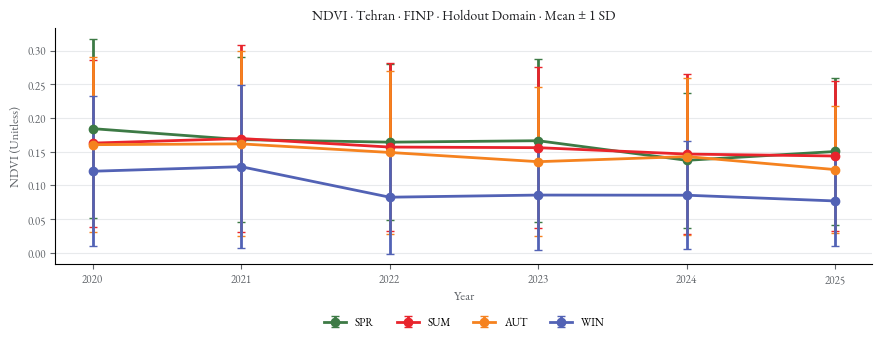

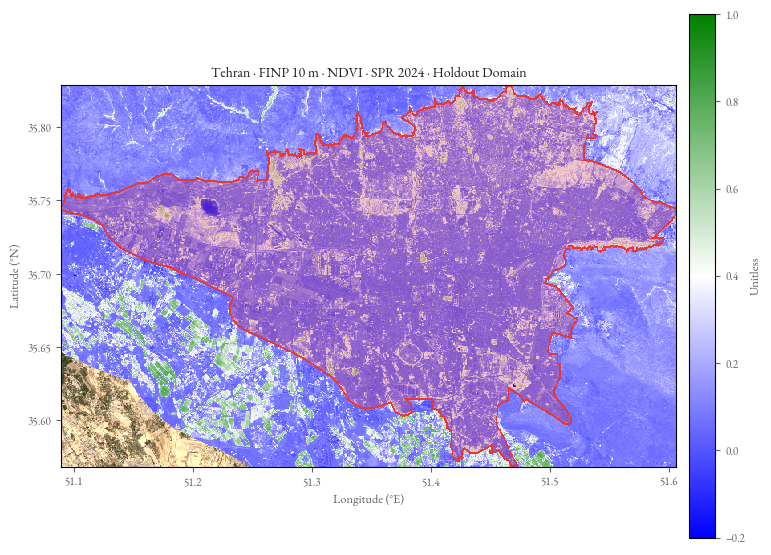

In [23]:
# ——————————————————————
# [10] Headless Analysis
# ——————————————————————

if RunHeadlessDemo:

    City , Tier , Layer , Kind = "Tehran" , "FINP" , "NDVI" , "Holdout"

    # [10.1] Regional Statistics: Every Season × Year

    Statistics = RegionalStatistics( City , Tier , Layer , Kind )

    display(Statistics.pivot( index = "Year" , columns = "Season" , values = "Mean" )[Cities[City].Seasons].round(3))

    # [10.2] Seasonal Trajectories (Mean ± 1 SD)

    Figure = PlotTemporal( Statistics , City , Tier , Layer , ValueColumn = "Mean" , ErrorColumn = "SD" , Title = f"{Layer} · {City} · {Tier} · {Kind} Domain · Mean ± 1 SD")

    try:

        Explorer._Polish(Figure)

    except Exception:

        pass

    plt.show()

    plt.close(Figure)

    # [10.3] One Map

    OriginalShow = plt.show

    def PolishShow( *Args , **Kwargs ):

        try:

            Explorer._Polish(plt.gcf())

        except Exception:

            pass

        return OriginalShow( *Args , **Kwargs )

    plt.show = PolishShow

    try:

        ShowLayer( City , Tier , Layer , SeasonCode = "SPR" , Year = 2024 , Kind = Kind )

    finally:

        plt.show = OriginalShow

    # [10.4] Save the Table

    # Statistics.to_csv(f"UC4D-{City}-{Tier}-{Layer}-{Kind}.csv", index=False)

else:

    print("\nSkipped (RunHeadlessDemo = False).")

---

#### **[11] Export to Zarr**

ExportZarr Materialises One or More Bands as a Chunked, Compressed Zarr Store. Requires xee<0.1.0 (pip install "xee<0.1.0"); the current default xee 0.1.x API uses crs_transform + shape_2d instead of scale + geometry, and the notebook's OpenXarray has not yet been ported to that API. The demo remains off by default for this reason.


[1] The Bands are Opened Lazily Through `xee` (§5.4), Clipped to a Domain's Bounding Box, Merged into One Dataset & Written Once.

[2] **Size Guard.** Before Anything is Requested, The Notebook Estimates The Pixel Count (`width × height × bands`) and Refuses Anything Above `MaxExportPixels` (§2) Unless You Pass `Force=True`. At 10 m, a Full City is Large, Start At a Coarser `ScaleMeters`.

[3] The Demonstration Is **Off By Default** (`RunZarrDemo = False`) Because it Writes to Disk.

In [24]:
# ———————————————————
# [11] Export to Zarr
# ———————————————————

def EstimateExport( CityName , Kind , ScaleMeters , BandCount ):

    """Pixel Count of an Export: Columns × Rows × Bands, on the Metre Grid Requested From Xee."""

    West, South, East, North = DomainBounds( CityName , Kind )

    Degrees = ScaleMeters / 111_320

    return int(np.ceil((East - West) / Degrees)) * int(np.ceil((North - South) / Degrees)) * BandCount

def ExportZarr( CityName , TierName , LayerIds , Path , Season = None , Year = None , ScaleMeters = None , Kind = "Holdout" , Force = False ):

    """

    Write One or More Bands of One Slice to a Zarr Store.

    Example

    -------

    >>> ExportZarr("Tehran", "FINP", [ "NDVI" ], "tehran-ndvi.zarr", Season="SPR", Year=2024, ScaleMeters=100)

    """

    ScaleMeters = ScaleMeters or Tiers[TierName].StatScale

    Client      = UC4D( CityName , TierName , Season , Year )

    Pixels      = EstimateExport( CityName , Kind , ScaleMeters , len(LayerIds) )

    print(f"\nExport Size : ~{Pixels:,} Pixels ({len(LayerIds)} Band(s) At {ScaleMeters} m Over The {Kind} Domain)")

    if Pixels > MaxExportPixels and not Force:

        raise ValueError(f"{Pixels:,} Pixels Exceeds MaxExportPixels ({MaxExportPixels:,.0f}). "

                         "Raise ScaleMeters, or Pass Force=True to Proceed Anyway.")

    Datasets    = [ Client.OpenXarray( LayerId , ScaleMeters , Kind ) for LayerId in LayerIds ]

    Unavailable = [ LayerId for LayerId , Data in zip( LayerIds , Datasets ) if Data is None ]

    if Unavailable:

        raise ValueError(f"Not Available At Tier {TierName}: {Unavailable}")

    xr.merge(Datasets).to_zarr( Path , mode = "w" , consolidated = True )

    print(f"\n✅ Wrote {', '.join(LayerIds)} · {Client!r} → {Path}")

if RunZarrDemo:

    ExportZarr( "Tehran" , "FINP" , [ "NDVI" , "Albedo" ] , ZarrDemoPath , Season = "SPR" , Year = 2024 , ScaleMeters = 100 )

    print(xr.open_zarr(ZarrDemoPath))

else:

    print("\nSkipped (RunZarrDemo = False). Set it To True in §2 to Write a Small Demo Store.")


Skipped (RunZarrDemo = False). Set it To True in §2 to Write a Small Demo Store.


---

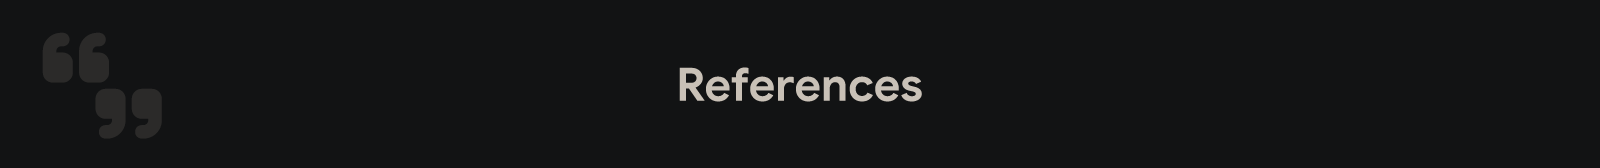

**[1] Software & Services**

- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., Moore, R., 2017. Google Earth Engine: Planetary-scale geospatial analysis for everyone. Remote Sens. Environ. 202, 18–27. https://doi.org/10.1016/j.rse.2017.06.031

- Hoyer, S., & Hamman, J. (2017). xarray: N-D labeled arrays and datasets in Python. *Journal of Open Research Software, 5*(1), 10. https://doi.org/10.5334/jors.148

- Google Research. *Xee: Xarray + Google Earth Engine* [Software]. https://github.com/google/Xee

- Zarr Developers. *Zarr: chunked, compressed, N-dimensional arrays* [Software]. https://zarr.dev

- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

**[2] Basemap**

- Copernicus Sentinel-2 Level-2A Surface Reflectance, Harmonized (`COPERNICUS/S2_SR_HARMONIZED`). European Union / ESA / Copernicus, via the Earth Engine Data Catalog.
